In [1]:
import sys
print(sys.executable)

C:\Users\i-sht\OneDrive\Desktop\UrFU_project\.venv\Scripts\python.exe


In [14]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
from ucimlrepo import fetch_ucirepo 

# **Первичный осмотр данных**

### 1. Смотрим на данные

In [17]:
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
df = pd.concat([X, y], axis=1)

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [18]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no


### 2. Информация по столбцам

Input variables:
   #### bank client data:
   1 - age (numeric)  
   2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                       "blue-collar","self-employed","retired","technician","services")   
   3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)  
   4 - education (categorical: "unknown","secondary","primary","tertiary")  
   5 - default: has credit in default? (binary: "yes","no")  
   6 - balance: average yearly balance, in euros (numeric)    
   7 - housing: has housing loan? (binary: "yes","no")  
   8 - loan: has personal loan? (binary: "yes","no")  
   #### related with the last contact of the current campaign:  
   9 - contact: contact communication type (categorical: "unknown","telephone","cellular")   
  10 - day: last contact day of the month (numeric)  
  11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")  
  12 - duration: last contact duration, in seconds (numeric)  
   #### other attributes:  
  13 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)  
  14 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)  
  15 - previous: number of contacts performed before this campaign and for this client (numeric)  
  16 - poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")  

  #### Output variable (desired target):  
  17 - y - has the client subscribed a term deposit? (binary: "yes","no")  



### 3. Оптимизируем память

In [19]:
memory_before = df.memory_usage(deep=True).sum()/1024**2
print(f"💾 Память до: {memory_before:.2f} MB")

💾 Память до: 24.56 MB


In [20]:
df.dtypes.value_counts()

str      10
int64     7
Name: count, dtype: int64

In [21]:
# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns
float_cols = df.select_dtypes(include=['float64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')


# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


💾 Память после: 22.70 MB
📉 Экономия: 7.6%


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int8 
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int32
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int8 
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int16
 12  campaign     45211 non-null  int8 
 13  pdays        45211 non-null  int16
 14  previous     45211 non-null  int16
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int16(3), int32(1), int8(3), str(10)
memory usage: 4.0 MB


### 4. Статистика

In [23]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [24]:
df.describe(include='str')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,44923,45211,43354,45211,45211,45211,32191,45211,8252,45211
unique,11,3,3,2,2,2,2,12,3,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,failure,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,4901,39922


# **Качество данных**

### 1. Анализ пропусков

In [25]:
mis_count = df.isna().sum()
mis_pct = (df.isna().mean()*100).round(2)
mis_df = pd.DataFrame({'Пропуски':mis_count,
    'Процент':mis_pct}).query('Пропуски > 0').sort_values(by='Процент',ascending=False)
print("📊 Пропуски в данных:")
mis_df

📊 Пропуски в данных:


,Пропуски,Процент
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


так как во всех столбцах есть категория unknown заполним пропуски этим значением

In [26]:
df[df['poutcome'].isna()]
df['poutcome'] = df['poutcome'].fillna('unknown')
df['contact'] = df['contact'].fillna('unknown')
df['education'] = df['education'].fillna('unknown')
df['job'] = df['job'].fillna('unknown')

In [27]:
mis_count = df[['poutcome','contact','education','job']].isna().sum()
mis_count

poutcome     0
contact      0
education    0
job          0
dtype: int64

### 2. Проверяем на выбросы

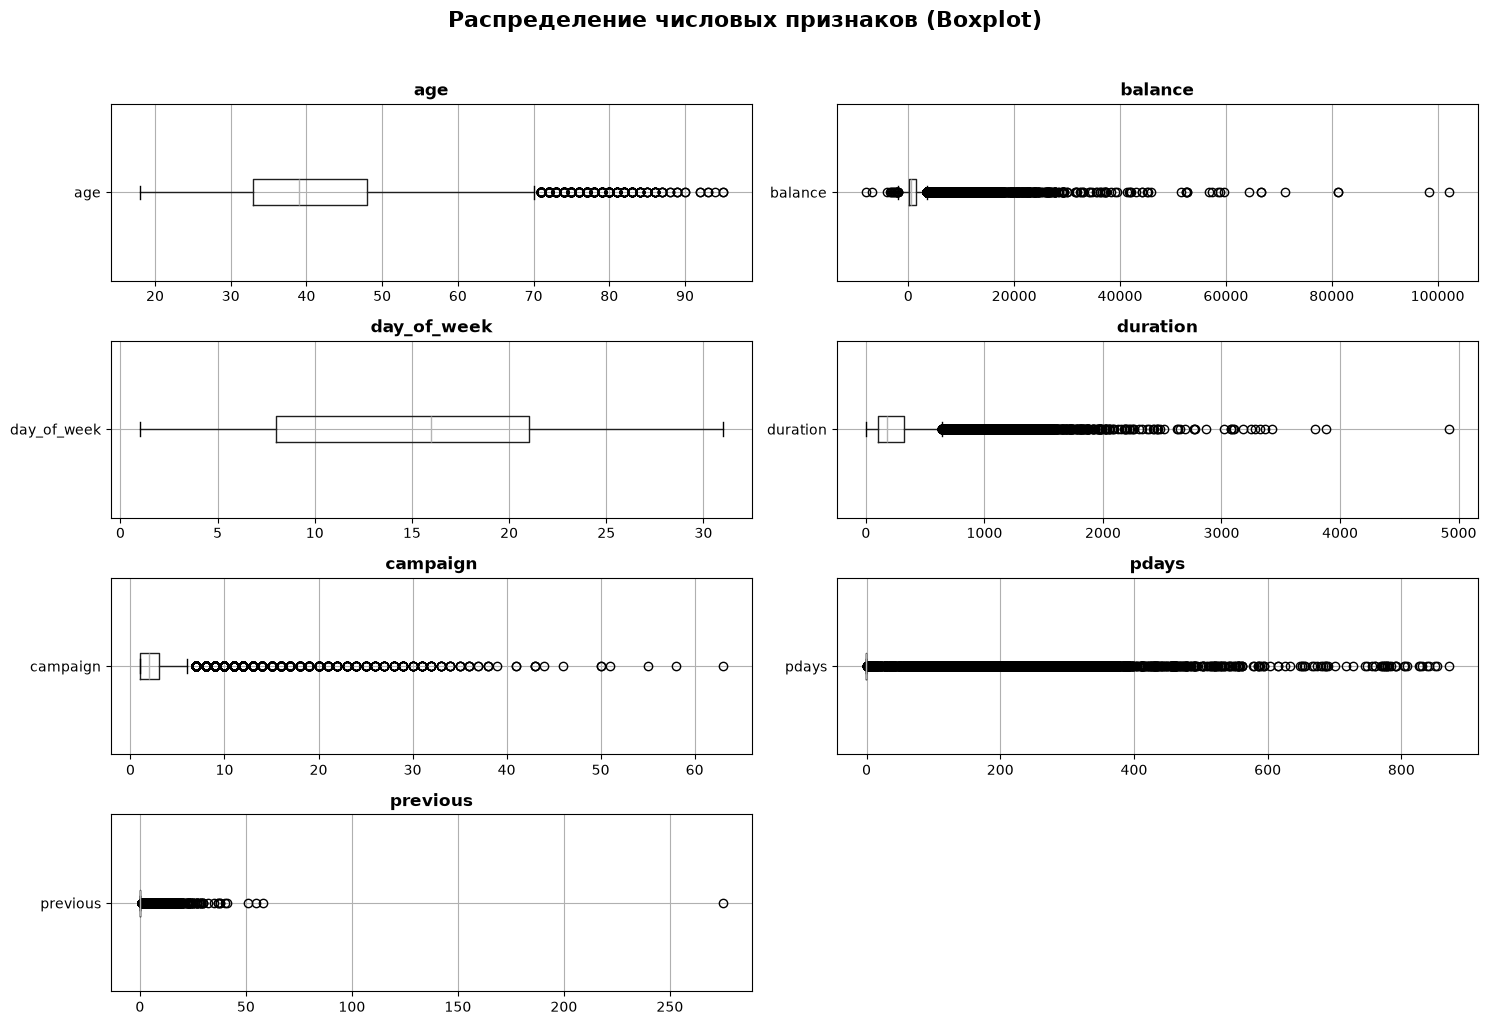

In [28]:
int_cols = ['age',	'balance',	'day_of_week',	'duration',	'campaign',	'pdays',	'previous']
fig,axes = plt.subplots(4,2,figsize=(15,10))
axes = axes.flatten()
axes[-1].set_visible(False)

for idx, col in enumerate(int_cols):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col,fontsize=12,fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot)', fontsize=16, fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

In [29]:
 # 1. balance — логарифмирование со знаком (сжимаем длинный хвост)
upper = df['balance'].quantile(0.99)
df['balance'] = np.clip(df['balance'], None, upper)

# 2. duration — Clipping по 99-му перцентилю
upper = df['duration'].quantile(0.99)
df['duration'] = np.clip(df['duration'], None, upper)

# 3. campaign — Clipping по 99-му перцентилю
upper = df['campaign'].quantile(0.99)
df['campaign'] = np.clip(df['campaign'], None, upper)

# 4. previous — Clipping по 99-му перцентилю
upper = df['previous'].quantile(0.99)
df['previous'] = np.clip(df['previous'], None, upper)

# 5. pdays — флаг + замена -1 на 0 (нейтральное значение)
df['was_contacted'] = (df['pdays'] != -1).astype(int)
df['pdays'] = df['pdays'].replace(-1, 0)

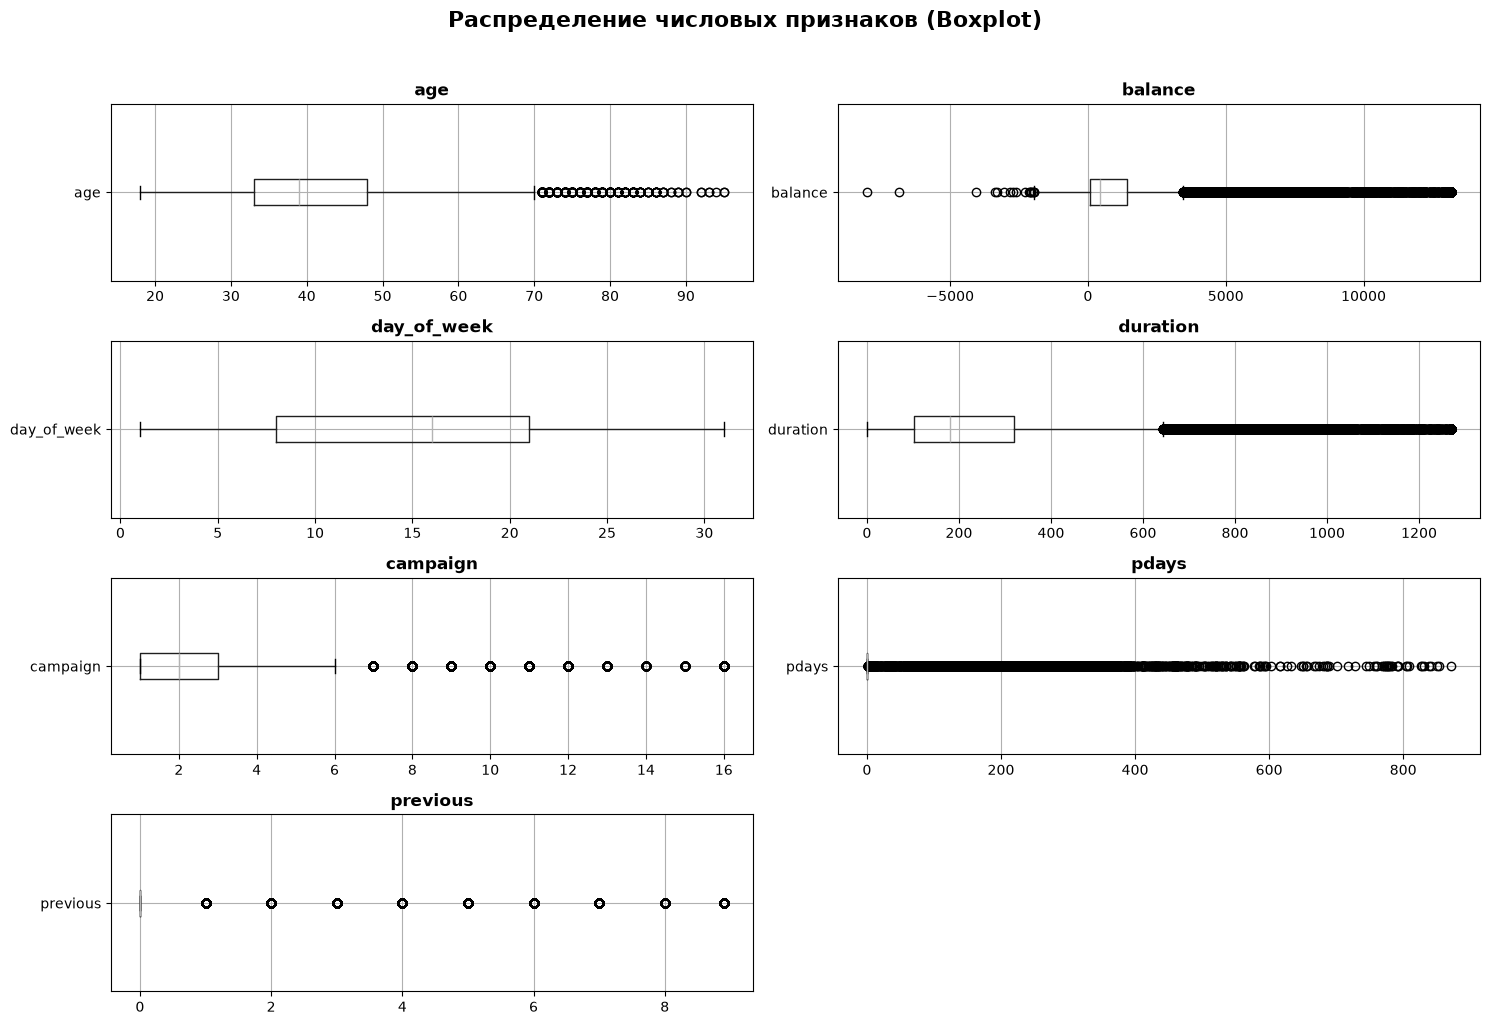

In [30]:
int_cols = ['age',	'balance',	'day_of_week',	'duration',	'campaign',	'pdays',	'previous']
fig,axes = plt.subplots(4,2,figsize=(15,10))
axes = axes.flatten()
axes[-1].set_visible(False)

for idx, col in enumerate(int_cols):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col,fontsize=12,fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot)', fontsize=16, fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

### **3. Анализ дубликатов**

In [32]:
# Полные дубликаты
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates:,} ({full_duplicates/len(df)*100:.2f}%)")

Полных дубликатов: 0 (0.00%)
